# Task 1: Anti-Cheat Pre-Filter (Binary Classification)
**รายวิชา:** CPE 342 Machine Learning  
**วัตถุประสงค์:** สร้างโมเดลคัดกรองบัญชีผู้เล่นต้องสงสัย เพื่อแยกผู้เล่นโกง (`1`) ออกจากผู้เล่นบริสุทธิ์ (`0`) โดยประเมินผลด้วย **Macro $F_2$ Score**

## 1. นำเข้าไลบรารีและโหลดข้อมูล (Import Libraries & Load Datasets)
โหลดชุดข้อมูลสำหรับสอนโมเดล (`train.csv`), ชุดข้อมูลทดสอบ (`test.csv`) และไฟล์ส่งคำตอบ (`submission.csv`) พร้อมตรวจสอบโครงสร้างเบื้องต้น

In [14]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import fbeta_score

# กำหนด Path ของไฟล์ข้อมูล
TRAIN_PATH = 'train.csv'
TEST_PATH = 'test.csv'
SUB_PATH = 'submission.csv'  # เปลี่ยนเป็นชื่อไฟล์รวมของทีมได้

# โหลดข้อมูลเข้าสู่ DataFrame
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sub_before = pd.read_csv(SUB_PATH)

print(f"Train shape: {train.shape} | Test shape: {test.shape}")

Train shape: (104000, 33) | Test shape: (25889, 32)


## 2. การเตรียมข้อมูลและคัดเลือกตัวแปร (Data Preprocessing & Feature Selection)
* **จัดการข้อมูลที่ไม่มีป้ายกำกับ:** ตัดแถวที่ค่าเป้าหมาย `is_cheater` เป็นค่าว่าง (`NaN`) ออกจากชุดข้อมูลฝึก เพื่อให้โมเดลเรียนรู้จากข้อมูลที่มีเฉลยถูกต้องเท่านั้น
* **คัดเลือกตัวแปร (Features):** เลือกใช้คุณลักษณะเชิงพฤติกรรมการเล่นทั้งหมด 31 ตัวแปร โดยตัด `player_id` ออกเพื่อป้องกันไม่ให้โมเดลจำรหัสผู้เล่น (Overfitting)
* **จัดการค่าว่างใน Features:** ใช้โมเดล LightGBM ซึ่งรองรับการจัดการค่า `NaN` ภายในโครงสร้างต้นไม้ได้โดยตรงโดยไม่บิดเบือนการกระจายตัวของข้อมูล

In [15]:
# ตัดแถวที่ไม่มีเฉลย (is_cheater เป็น NaN) ออกก่อนเทรน
train_labeled = train.dropna(subset=['is_cheater']).reset_index(drop=True)

# เลือกใช้ทั้ง 31 features (ไม่เอา player_id)
features = [col for col in test.columns if col != 'player_id']

X = train_labeled[features]
y = train_labeled['is_cheater'].astype(int)
X_test = test[features]

print(f"จำนวนข้อมูลที่มีเฉลยพร้อมใช้งาน: {len(train_labeled)} แถว | จำนวน Features: {len(features)} ตัว")

จำนวนข้อมูลที่มีเฉลยพร้อมใช้งาน: 90816 แถว | จำนวน Features: 31 ตัว


### การแสดงผลข้อมูลเชิงสำรวจ (Exploratory Data Analysis - EDA)
* **กราฟซ้าย (Class Distribution):** แสดงสัดส่วนผู้เล่นปกติ (`0`: 59,091 คน) เทียบกับผู้เล่นโกง (`1`: 31,725 คน) ซึ่งมีความไม่สมดุลของคลาส (ประมาณ 65% ต่อ 35%) จึงจำเป็นต้องใช้ `StratifiedKFold` และการปรับจุดตัด (Threshold Tuning)
* **กราฟขวา (Key Feature Distributions):** เปรียบเทียบการกระจายตัวของ `account_age_days` และ `friend_network_size` แสดงให้เห็นว่าบัญชีคนโกงมักมีอายุบัญชีสั้นกว่าและมีเครือข่ายเพื่อนน้อยกว่ากลุ่มผู้เล่นทั่วไป

/tmp/ipykernel_3981/1302212140.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Legitimate (0)', 'Cheater (1)'], y=counts.values, ax=axes[0], palette=['#4C72B0', '#DD8452'])


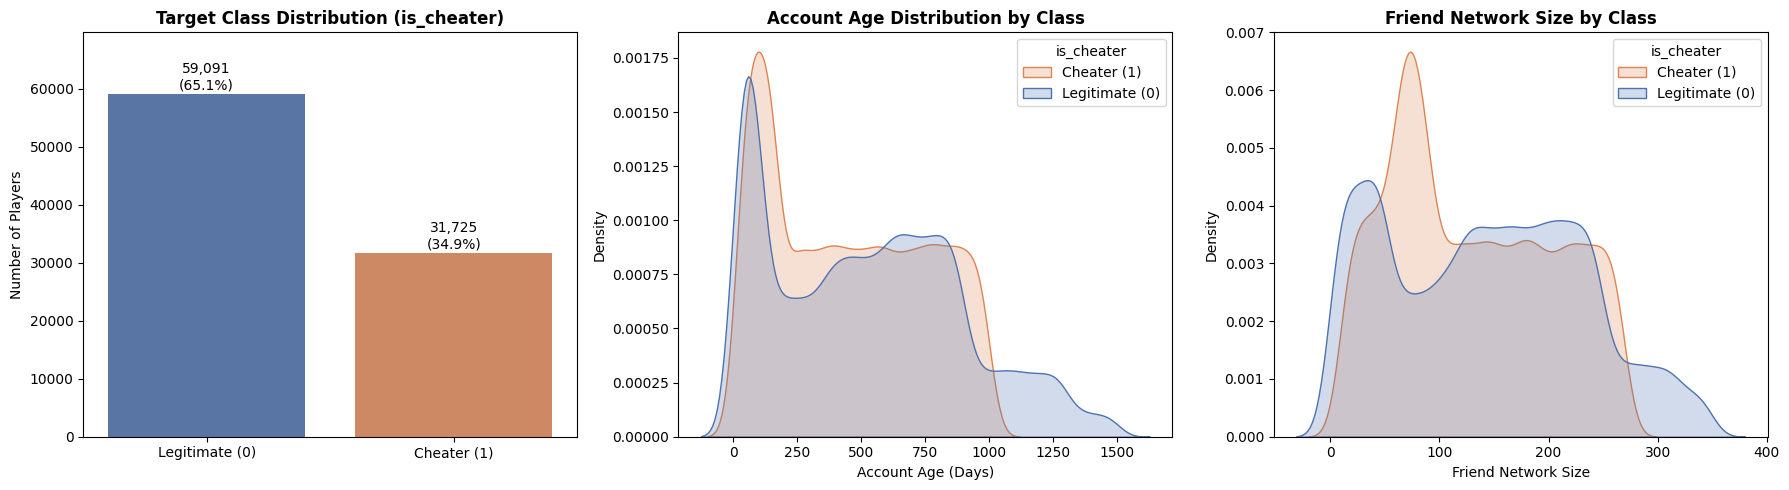

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# กราฟที่ 1: สัดส่วนคลาสเป้าหมาย (is_cheater)
counts = y.value_counts().sort_index()
sns.barplot(x=['Legitimate (0)', 'Cheater (1)'], y=counts.values, ax=axes[0], palette=['#4C72B0', '#DD8452'])
axes[0].set_title('Target Class Distribution (is_cheater)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Players')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 800, f"{v:,}\n({v/len(y)*100:.1f}%)", ha='center', fontsize=10)
axes[0].set_ylim(0, max(counts.values) * 1.18)

# กราฟที่ 2: การกระจายตัวของอายุบัญชี (account_age_days)
sns.kdeplot(data=train_labeled, x='account_age_days', hue='is_cheater', fill=True, common_norm=False, ax=axes[1], palette=['#4C72B0', '#DD8452'])
axes[1].set_title('Account Age Distribution by Class', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Account Age (Days)')
axes[1].legend(title='is_cheater', labels=['Cheater (1)', 'Legitimate (0)'])

# กราฟที่ 3: การกระจายตัวของจำนวนเพื่อน (friend_network_size)
sns.kdeplot(data=train_labeled, x='friend_network_size', hue='is_cheater', fill=True, common_norm=False, ax=axes[2], palette=['#4C72B0', '#DD8452'])
axes[2].set_title('Friend Network Size by Class', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Friend Network Size')
axes[2].legend(title='is_cheater', labels=['Cheater (1)', 'Legitimate (0)'])

plt.tight_layout()
plt.show()

## 3. การฝึกสอนโมเดลด้วย Stratified 5-Fold Cross-Validation
ใช้ **LightGBM Classifier** ร่วมกับการแบ่งข้อมูลแบบ **Stratified 5-Fold Cross-Validation** เพื่อรักษาสัดส่วนของคลาส `0` และ `1` ให้เท่ากันในทุก Fold พร้อมใช้เทคนิค **Early Stopping** (หยุดเทรนเมื่อค่า Loss ไม่ลดลงติดต่อกัน 50 รอบ) เพื่อป้องกันปัญหา Overfitting และนำค่าความน่าจะเป็น (Probability) จากทั้ง 5 โมเดลมาเฉลี่ยรวมกันสำหรับทำนายชุดทดสอบ

In [17]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(train_labeled))
test_preds = np.zeros(len(test))

lgb_params = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'n_estimators': 1000,
    'random_state': 42,
    'verbose': -1
}

print("กำลังเริ่มเทรนโมเดล 5-Fold...")
importances = np.zeros(len(features))
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(**lgb_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    oof_preds[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds += model.predict_proba(X_test)[:, 1] / skf.n_splits
    print(f"  - เสร็จสิ้น Fold {fold + 1}/5")
    importances += model.feature_importances_ / skf.n_splits

กำลังเริ่มเทรนโมเดล 5-Fold...
  - เสร็จสิ้น Fold 1/5
  - เสร็จสิ้น Fold 2/5
  - เสร็จสิ้น Fold 3/5
  - เสร็จสิ้น Fold 4/5
  - เสร็จสิ้น Fold 5/5


### การวิเคราะห์ความสำคัญของตัวแปร (Feature Importance)
แสดง 15 อันดับตัวแปรที่โมเดล LightGBM ใช้ในการแบ่งเงื่อนไขการตัดสินใจมากที่สุด เพื่ออธิบายว่าโมเดลใช้ปัจจัยใดในการแยกคนโกงออกจากผู้เล่นปกติ

/tmp/ipykernel_3981/1543675427.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, x='importance', y='feature', palette='viridis')


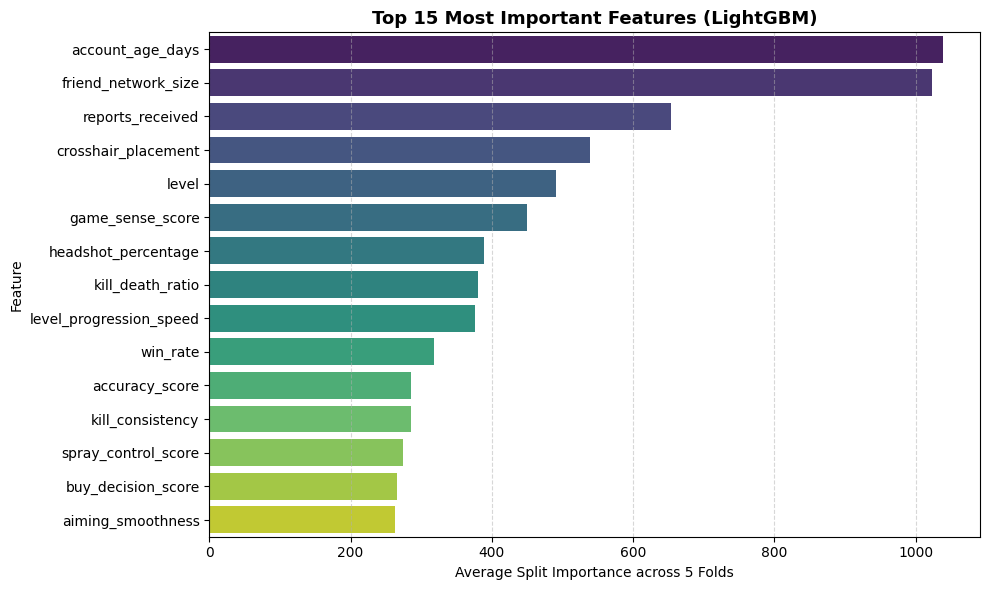

In [18]:
imp_df = pd.DataFrame({'feature': features, 'importance': importances}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, x='importance', y='feature', palette='viridis')
plt.title('Top 15 Most Important Features (LightGBM)', fontsize=13, fontweight='bold')
plt.xlabel('Average Split Importance across 5 Folds')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. การค้นหาจุดตัดที่เหมาะสมที่สุดสำหรับ Macro $F_2$ Score
เนื่องจากโจทย์กำหนดเกณฑ์วัดผลเป็น **Macro $F_2$ Score** ซึ่งให้ความสำคัญกับค่า **Recall** (การตรวจจับคนโกงให้ครบถ้วน) มากกว่า Precision การใช้จุดตัดมาตรฐานที่ `0.50` จึงไม่ใช่จุดที่ดีที่สุด ขั้นตอนนี้จึงทำการค้นหาค่า Threshold ในช่วง `0.10` ถึง `0.89` บนผลทำนาย Out-Of-Fold (`oof_preds`) เพื่อเลือกจุดตัดที่ให้คะแนน Macro $F_2$ สูงที่สุด

In [19]:
best_thresh = 0.5
best_f2 = 0.0

for thresh in np.arange(0.10, 0.90, 0.01):
    score = fbeta_score(y, (oof_preds >= thresh).astype(int), beta=2, average='macro')
    if score > best_f2:
        best_f2 = score
        best_thresh = thresh

default_f2 = fbeta_score(y, (oof_preds >= 0.50).astype(int), beta=2, average='macro')

print("--- ผลการประเมิน (Local CV) ---")
print(f"คะแนน Macro F2 (เกณฑ์ปกติ 0.50)       : {default_f2:.5f}")
print(f"คะแนน Macro F2 (เกณฑ์ที่ดีที่สุด {best_thresh:.2f}) : {best_f2:.5f}")

--- ผลการประเมิน (Local CV) ---
คะแนน Macro F2 (เกณฑ์ปกติ 0.50)       : 0.75752
คะแนน Macro F2 (เกณฑ์ที่ดีที่สุด 0.37) : 0.77872


### การวิเคราะห์ผลลัพธ์และจุดตัดคะแนน (Threshold Curve & Confusion Matrix)
* **กราฟซ้าย (Threshold Optimization Curve):** แสดงการเปลี่ยนแปลงของคะแนน Macro $F_2$ ในแต่ละระดับ Threshold ชี้ให้เห็นจุดสูงสุดที่เหมาะสมกว่าค่าเริ่มต้น `0.50`
* **กราฟขวา (Confusion Matrix):** แสดงจำนวนการทายถูกและทายผิดในแต่ละคลาส ณ จุดตัดที่ดีที่สุด (`best_thresh`)

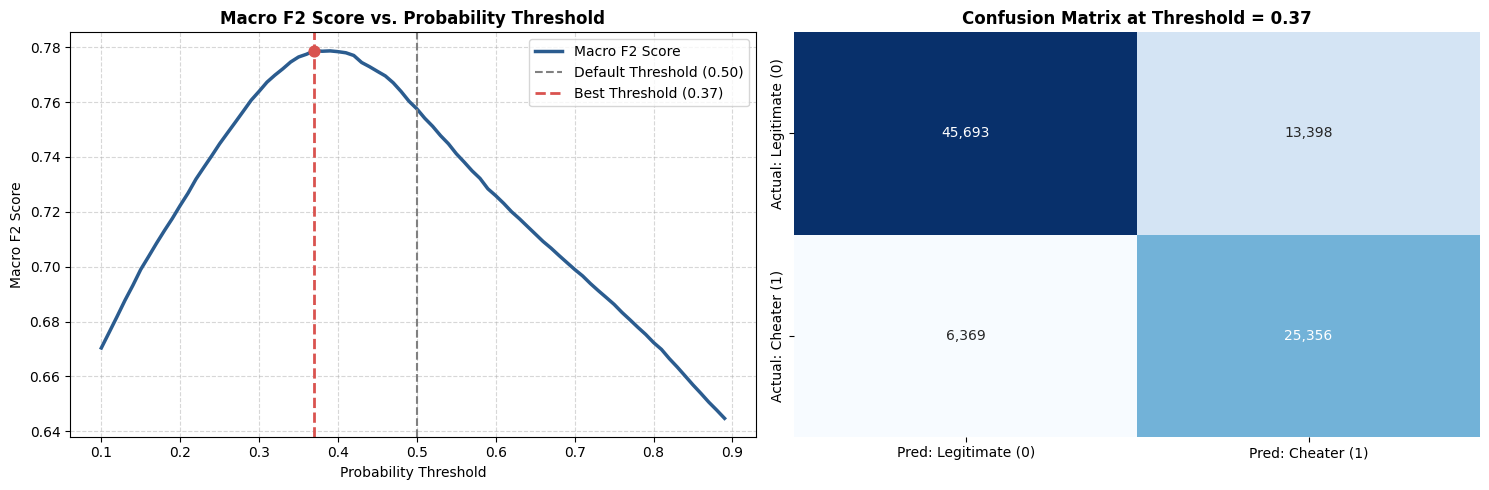

In [20]:
from sklearn.metrics import confusion_matrix

thresholds = np.arange(0.10, 0.90, 0.01)
f2_scores = [fbeta_score(y, (oof_preds >= t).astype(int), beta=2, average='macro') for t in thresholds]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# กราฟที่ 1: เส้นโค้ง Macro F2 ตามค่า Threshold
axes[0].plot(thresholds, f2_scores, color='#2b5c8f', linewidth=2.5, label='Macro F2 Score')
axes[0].axvline(0.50, color='gray', linestyle='--', label='Default Threshold (0.50)')
axes[0].axvline(best_thresh, color='#d9534f', linestyle='--', linewidth=2, label=f'Best Threshold ({best_thresh:.2f})')
axes[0].scatter([best_thresh], [best_f2], color='#d9534f', s=60, zorder=5)
axes[0].set_title('Macro F2 Score vs. Probability Threshold', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Probability Threshold')
axes[0].set_ylabel('Macro F2 Score')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# กราฟที่ 2: Confusion Matrix ณ Best Threshold
y_pred_opt = (oof_preds >= best_thresh).astype(int)
cm = confusion_matrix(y, y_pred_opt)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Pred: Legitimate (0)', 'Pred: Cheater (1)'],
            yticklabels=['Actual: Legitimate (0)', 'Actual: Cheater (1)'])
axes[1].set_title(f'Confusion Matrix at Threshold = {best_thresh:.2f}', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. บันทึกคำตอบลงคอลัมน์ `task1` และตรวจสอบความปลอดภัยของไฟล์
แปลงค่าความน่าจะเป็นของชุดทดสอบเป็นคำตอบ (`0` หรือ `1`) โดยใช้ `best_thresh` จากขั้นตอนที่ 4 จากนั้นเขียนทับเฉพาะคอลัมน์ `task1` พร้อมตรวจสอบว่าขนาดไฟล์ถูกต้อง ไม่มีค่าว่าง (`NaN`) และไม่กระทบคำตอบของงานส่วนอื่น (`task2`–`task5`) ก่อนบันทึกไฟล์

In [21]:
sub_after = sub_before.copy()
sub_after['task1'] = (test_preds >= best_thresh).astype(int)

# ตรวจสอบว่าคอลัมน์อื่น (id, task2, task3, task4, task5) ยังคงเดิม 100%
other_cols = ['id', 'task2', 'task3', 'task4', 'task5']
is_safe = sub_before[other_cols].equals(sub_after[other_cols])

print("--- ผลการตรวจเช็กไฟล์ก่อนบันทึก ---")
print("1. ขนาดไฟล์ตรงตามต้นฉบับไหม             :", sub_after.shape == sub_before.shape, sub_after.shape)
print("2. คอลัมน์ task1 มีค่าว่างไหม               :", sub_after['task1'].isnull().sum())
print("3. คำตอบข้ออื่นของเพื่อนอยู่ครบ 100% ไหม     :", is_safe)
print("4. สัดส่วนคำทำนาย task1 (0 vs 1) :\n", sub_after['task1'].value_counts(normalize=True).round(4))

if is_safe and sub_after['task1'].isnull().sum() == 0:
    sub_after.to_csv(SUB_PATH, index=False)
    print(f"\n[สำเร็จ] บันทึกคำตอบลงใน '{SUB_PATH}' เรียบร้อยแล้ว!")
else:
    print("\n[คำเตือน] พบความผิดปกติ ระบบจึงยังไม่บันทึกทับไฟล์เดิม กรุณาตรวจสอบอีกครั้ง")

--- ผลการตรวจเช็กไฟล์ก่อนบันทึก ---
1. ขนาดไฟล์ตรงตามต้นฉบับไหม             : True (25889, 6)
2. คอลัมน์ task1 มีค่าว่างไหม               : 0
3. คำตอบข้ออื่นของเพื่อนอยู่ครบ 100% ไหม     : True
4. สัดส่วนคำทำนาย task1 (0 vs 1) :
 task1
0    0.5779
1    0.4221
Name: proportion, dtype: float64

[สำเร็จ] บันทึกคำตอบลงใน 'submission.csv' เรียบร้อยแล้ว!
